In [1]:
!pip install pyarrow




[notice] A new release of pip is available: 25.0 -> 25.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import pyarrow.feather as feather
train = feather.read_feather("/Users/fizzausman/Downloads/masq_train.feather")
test = feather.read_feather("/Users/fizzausman/Downloads/masq_test.feather")


In [3]:
print(train)

      D_DEPDYS GENDER  Leeftijd DEMOG1 DEMOG2 DEMOG3 DEMOG4 DEMOG5 DEMOG6  \
0            1      v        27      2      5      3      1      6      1   
1            1      v        59      1      2      2      1      2      1   
2            0      v        55     NA     NA     NA     NA     NA     NA   
3            1      v        45      2      4      4      2      6      1   
4            1      m        58      1      2      1      1      1      1   
...        ...    ...       ...    ...    ...    ...    ...    ...    ...   
1793         0      v        44      2      4      2      1      6      1   
1794         1      m        57      4      2      2      1      6      1   
1795         1      m        72      1      2      2      1      4      1   
1796         1      v        48      2      1      4      1      6      1   
1797         0      m        24      4      5      3      1      5      1   

     DEMOG7  ... MASQ81  MASQ82  MASQ83  MASQ84  MASQ85  MASQ86  MASQ87  \


In [4]:
print(test)

      D_DEPDYS GENDER  Leeftijd DEMOG1 DEMOG2 DEMOG3 DEMOG4 DEMOG5 DEMOG6  \
0            0      m        30      4      1      3      1      3      1   
1            0      v        48      1      3      2      1      6      1   
2            1      m        41      4      5      2      1      6      1   
3            1      v        26      1      2      3      2      6      1   
4            0      v        46      1      3      2      2      2      1   
...        ...    ...       ...    ...    ...    ...    ...    ...    ...   
1793         1      m        39      1      3      2      1      3      1   
1794         1      v        31      4      4      3      1      6      1   
1795         1      v        20      4      5      2      2      3      1   
1796         1      m        45      1      3      1      1      6      1   
1797         1      v        46      4      1      4      1      2      1   

     DEMOG7  ... MASQ81  MASQ82  MASQ83  MASQ84  MASQ85  MASQ86  MASQ87  \


In [5]:
non_numeric_cols = train.select_dtypes(exclude=['number']).columns
print("The Non-numeric columns are:", non_numeric_cols.tolist())

The Non-numeric columns are: ['GENDER', 'DEMOG1', 'DEMOG2', 'DEMOG3', 'DEMOG4', 'DEMOG5', 'DEMOG6', 'DEMOG7', 'DEMOG8']


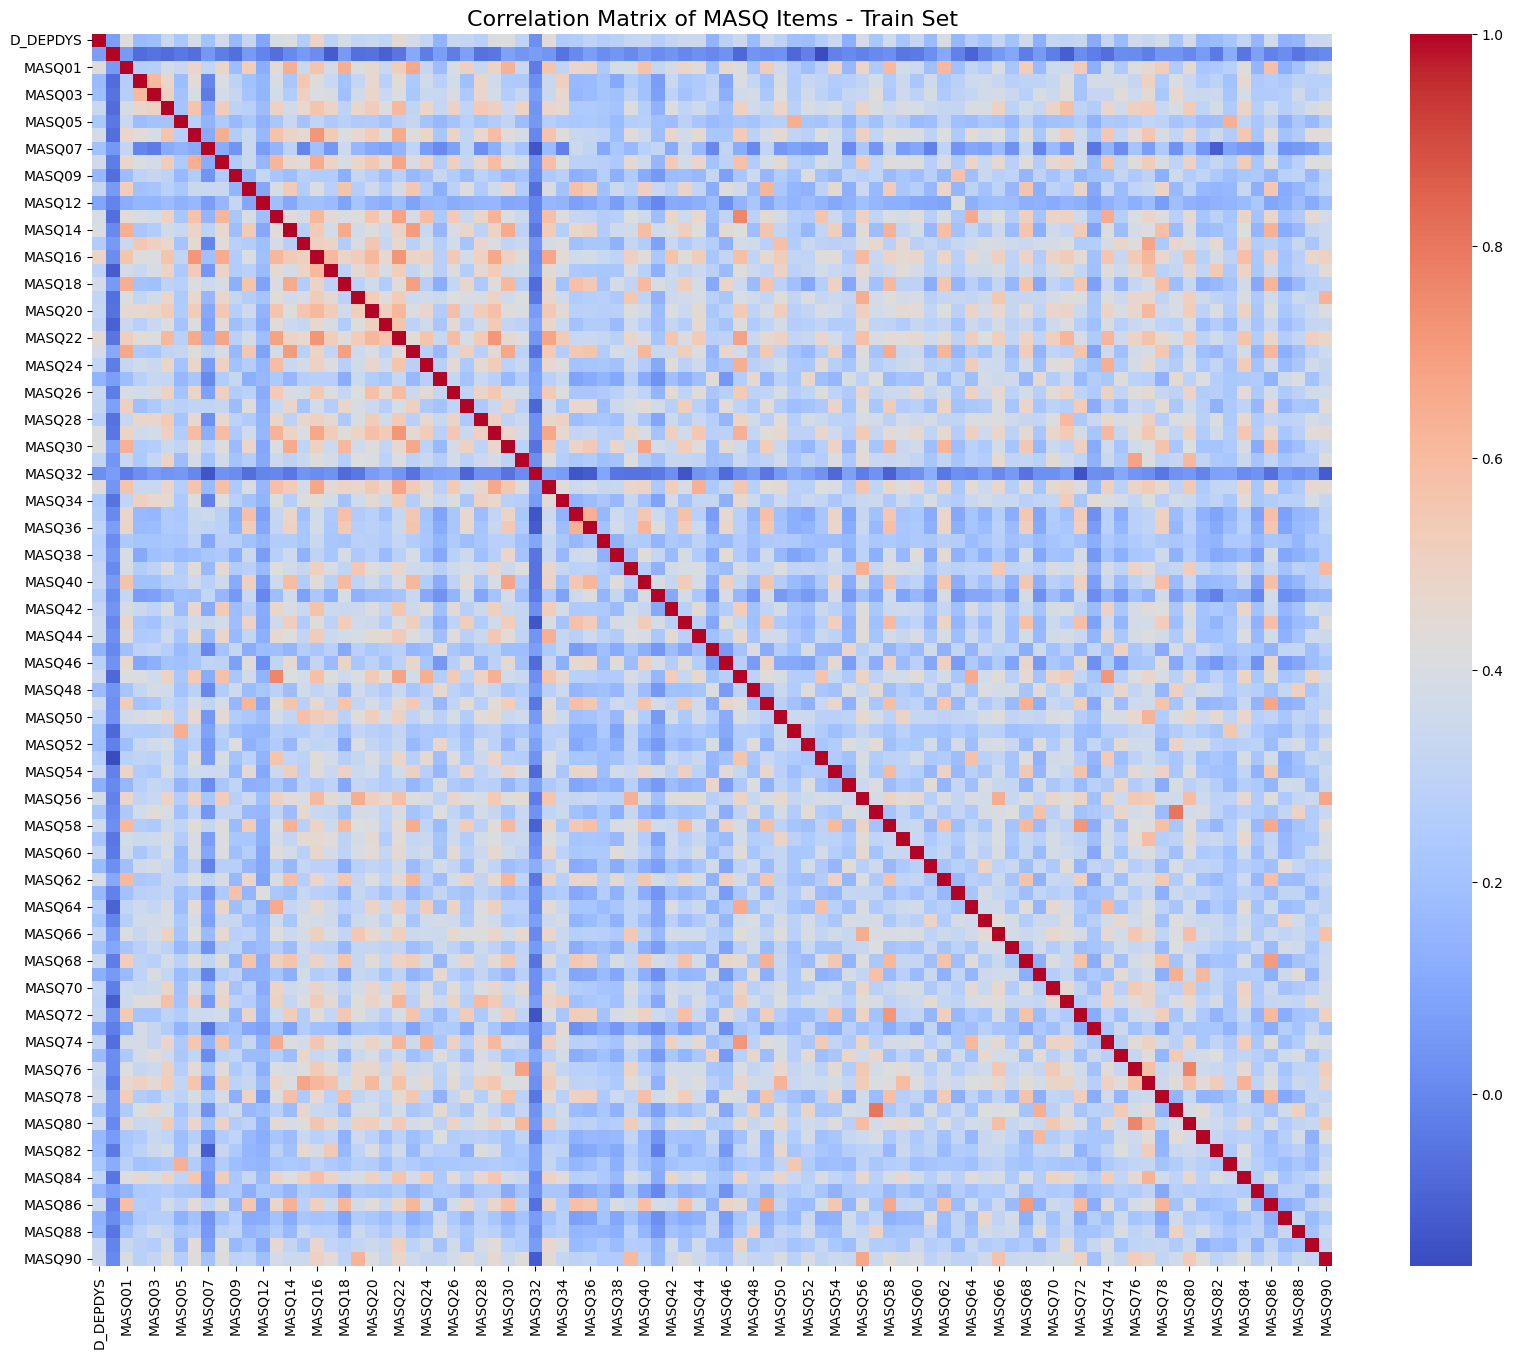

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numeric_train_cm = train.select_dtypes(include=['number'])
correlation_matrix = numeric_train_cm.corr()


plt.figure(figsize=(20, 16))  # Increase figure size
sns.heatmap(correlation_matrix, cmap="coolwarm", fmt=".2f", annot=False)  # Remove `annot=True`
plt.title("Correlation Matrix of MASQ Items - Train Set", fontsize=16)
plt.xticks(rotation=90)  # Rotate labels for readability
plt.yticks(rotation=0)
plt.show()

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
train_numeric = train.select_dtypes(include=[float, int])

vif_data = pd.DataFrame()
vif_data["MASQ_variables"] = train_numeric.columns
vif_data["Variance_IF"] = [variance_inflation_factor(train_numeric.values, i) for i in range(train_numeric.shape[1])]

print(vif_data.sort_values(by="Variance_IF", ascending=False).head(90))

   MASQ_variables  Variance_IF
58         MASQ58    61.047021
86         MASQ86    52.444590
23         MASQ23    50.482539
35         MASQ35    47.754812
11         MASQ11    47.367952
..            ...          ...
37         MASQ37     5.157020
85         MASQ85     4.963590
73         MASQ73     4.941239
12         MASQ12     4.620550
32         MASQ32     3.889054

[90 rows x 2 columns]


In [8]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)

print(vif_data.sort_values(by="Variance_IF", ascending=False))

   MASQ_variables  Variance_IF
58         MASQ58    61.047021
86         MASQ86    52.444590
23         MASQ23    50.482539
35         MASQ35    47.754812
11         MASQ11    47.367952
36         MASQ36    46.244577
72         MASQ72    45.976203
18         MASQ18    43.239533
49         MASQ49    43.203236
14         MASQ14    42.629174
68         MASQ68    42.150902
40         MASQ40    36.640434
43         MASQ43    36.012470
54         MASQ54    30.737578
2          MASQ01    30.456976
30         MASQ30    30.057043
78         MASQ78    29.487674
77         MASQ77    26.637945
46         MASQ46    25.411221
62         MASQ62    24.587900
76         MASQ76    21.536344
16         MASQ16    21.494346
27         MASQ27    20.989680
80         MASQ80    19.009713
56         MASQ56    18.260676
84         MASQ84    18.100923
90         MASQ90    17.805840
6          MASQ05    17.179144
22         MASQ22    17.156868
15         MASQ15    17.057739
38         MASQ38    16.608128
7       

In [9]:
total_rows = vif_data.shape[0]

g10_vif_rows = vif_data[vif_data["Variance_IF"] > 10].shape[0]

print(f"Total number of rows: {total_rows}")
print(f"Number of rows with Variance_IF > 10: {g10_vif_rows}")

Total number of rows: 91
Number of rows with Variance_IF > 10: 55


In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

train_predictors = train.drop(columns=['D_DEPDYS'])
train_response = train['D_DEPDYS']
test_predictors = test.drop(columns=['D_DEPDYS'])
test_response = test['D_DEPDYS']

non_numeric_cols = train_predictors.select_dtypes(exclude=['number']).columns.tolist()
numeric_cols = train_predictors.select_dtypes(include=['number']).columns.tolist()

transformer = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(), non_numeric_cols)
    ])

ridge_model = Pipeline(steps=[('transformer', transformer), ('ridge', Ridge(alpha=1.0))])
lasso_model = Pipeline(steps=[('transformer', transformer), ('lasso', Lasso(alpha=0.1))])
elastic_net_model = Pipeline(steps=[('transformer', transformer), ('elasticnet', ElasticNet(alpha=0.2, l1_ratio=0.5))])

ridge_model.fit(train_predictors,train_response)
lasso_model.fit(train_predictors, train_response)
elastic_net_model.fit(train_predictors, train_response)

ridge_prediction = ridge_model.predict(test_predictors)
lasso_prediction = lasso_model.predict(test_predictors)
elastic_net_prediction = elastic_net_model.predict(test_predictors)

ridge_mse = mean_squared_error(test_response, ridge_prediction)
lasso_mse = mean_squared_error(test_response, lasso_prediction)
elastic_net_mse = mean_squared_error(test_response, elastic_net_prediction)

print("Ridge MSE:", ridge_mse)
print("Lasso MSE:", lasso_mse)
print("Elastic Net MSE:", elastic_net_mse)

Ridge MSE: 0.17100574870642662
Lasso MSE: 0.18516323612162647
Elastic Net MSE: 0.18628508480244327


In [15]:
pip install glmnet

  Preparing metadata (setup.py) ... error
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> [22 lines of output]
      /private/var/folders/h3/mpj_h6hd1x1_sbmvhjc1v7jw0000gn/T/pip-install-tmul2ghs/glmnet_eafa507e818b4f68b94150d6e4ecbcca/setup.py:14: DeprecationWarning:
      
        `numpy.distutils` is deprecated since NumPy 1.23.0, as a result
        of the deprecation of `distutils` itself. It will be removed for
        Python >= 3.12. For older Python versions it will remain present.
        It is recommended to use `setuptools < 60.0` for those Python versions.
        For more details, see:
          https://numpy.org/devdocs/reference/distutils_status_migration.html
      
      
        from numpy.distutils.core import Extension, setup
      /opt/anaconda3/lib/python3.11/site-packages/setuptools/__init__.py:80: _DeprecatedInstaller: setuptools.installer and fetch_build_eggs are deprecated.
      !!
      
 

In [20]:
pip install pyglmnet


[notice] A new release of pip is available: 25.0 -> 25.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [49]:
import numpy as np
from pyglmnet import GLM
from sklearn.model_selection import KFold
from joblib import Parallel, delayed

scaler = StandardScaler()
train_predictors = scaler.fit_transform(train_predictors)

kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_results = []

alpha_values = np.logspace(-3, 0, 5)

def train_and_evaluate(alpha, train_index, val_index):
    X_train, X_val = train_predictors[train_index], train_predictors[val_index]
    y_train, y_val = train_response[train_index], train_response[val_index]
    
    model = GLM(solver='cdfast', alpha=alpha, max_iter=1000)  
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_val)
    mse = mean_squared_error(y_val, y_pred)
    return mse


for alpha in alpha_values:
    each_fold_mse = Parallel(n_jobs=-1)(delayed(train_and_evaluate)(alpha, train_index, val_index) 
                                         for train_index, val_index in kf.split(train_predictors))
    
    mean_mse = np.mean(each_fold_mse)
    cv_results.append((alpha, mean_mse))
    print(f"Alpha: {alpha}, Mean MSE: {mean_mse}")


best_alpha, best_mse = min(cv_results, key=lambda x: x[1])
print(f"Best alpha (lambda): {best_alpha}, with Mean MSE: {best_mse}")

best_model = GLM(solver='cdfast', alpha=best_alpha, max_iter=1000)
best_model.fit(train_predictors, train_response)

predictions = best_model.predict(train_predictors)
print(f"Predictions: {predictions}")


Alpha: 0.001, Mean MSE: 0.17944851795640737
Alpha: 0.005623413251903491, Mean MSE: 0.17928525562920383
Alpha: 0.03162277660168379, Mean MSE: 0.17537642036236245
Alpha: 0.1778279410038923, Mean MSE: 0.17904471873744968
Alpha: 1.0, Mean MSE: 0.2034587565396281
Best alpha (lambda): 0.03162277660168379, with Mean MSE: 0.17537642036236245
Predictions: [1.13691134 1.03564492 0.08380968 ... 0.99556579 1.00347378 0.4860953 ]


In [52]:
test_predictors.shape

(1798, 99)

In [53]:
test_response.shape

(1798,)

In [60]:
print(test_predictors[:5])  # Check the first few rows


[['m' 30 '4' '1' '3' '1' '3' '1' '1' '1' 3 3 2 2 2 3 4 4 1 4 1 2 4 1 2 2
  5 2 2 1 3 4 2 1 1 3 1 2 4 1 3 2 1 4 5 3 2 3 4 4 3 3 2 1 4 2 1 3 2 1 1 3
  4 1 3 1 4 1 1 1 4 1 2 1 1 2 3 1 1 2 4 1 3 2 1 2 4 1 3 1 1 1 2 1 3 1 1 1
  2]
 ['v' 48 '1' '3' '2' '1' '6' '1' '1' '1' 4 4 3 1 5 3 3 2 3 3 1 1 3 3 2 1
  3 4 1 1 1 5 2 2 1 2 1 1 2 2 2 1 3 5 5 1 3 1 4 2 2 3 1 4 3 1 3 4 1 4 3 1
  3 4 1 1 5 3 1 1 4 3 2 1 1 1 3 4 1 1 3 2 2 4 2 3 4 1 2 4 3 2 2 3 4 2 1 1
  2]
 ['m' 41 '4' '5' '2' '1' '6' '1' '1' '1' 3 3 2 3 2 2 2 2 1 5 1 2 3 3 2 4
  3 4 2 3 3 3 1 1 1 4 1 3 3 2 4 2 1 4 3 1 2 4 3 2 3 4 3 1 5 1 1 5 2 1 3 3
  4 1 2 1 3 3 1 1 3 1 2 1 1 1 3 1 2 2 5 1 1 3 4 2 4 1 4 3 2 2 2 3 4 1 1 2
  3]
 ['v' 26 '1' '2' '3' '2' '6' '1' '1' '1' 3 2 1 1 2 4 5 4 4 5 5 3 5 2 4 4
  4 4 4 2 4 5 2 1 4 5 2 3 4 3 1 3 1 5 5 5 4 4 4 4 4 5 2 1 5 4 1 4 2 4 1 5
  5 1 3 1 5 2 3 1 5 4 4 1 4 1 5 1 3 1 5 1 4 1 3 3 4 1 2 1 1 1 4 1 5 1 1 1
  5]
 ['v' 46 '1' '3' '2' '2' '2' '1' '1' '1' 2 1 1 1 2 1 2 1 1 2 2 1 2 1 1 1
  2 1 2 1 1 2 2 1 1 4 1

In [66]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer

test_predictors[test_predictors == 'NA'] = np.nan
imputer = SimpleImputer(strategy='mean')  
test_predictors = imputer.fit_transform(test_predictors)
encoder = LabelEncoder()
test_predictors[:, 0] = encoder.fit_transform(test_predictors[:, 0])
test_predictors = test_predictors.astype(np.float64)  
test_response = np.array(test_response)
test_predictions = best_model.predict(test_predictors)
test_predictions_class = (test_predictions >= 0.5).astype(int)
misclassification_rate = np.mean(test_predictions_class != test_response)
print(f"Misclassification Rate (MCR): {misclassification_rate:.4f}")


Misclassification Rate (MCR): 0.5451


In [70]:
feature_names = [
    "Item 1: Anhedonic Depression", "Item 2: General Distress Anxiety", "Item 3: Anxious Arousal", 
    "Item 4: General Distress Mixed", "Item 5: General Distress Mixed", "Item 6: General Distress Depression", 
    "Item 7: General Distress Depression", "Item 8: General Distress Depression", "Item 9: General Distress Anxiety", 
    "Item 10: General Distress Depression", "Item 11: General Distress Mixed", "Item 12: General Distress Anxiety", 
    "Item 13: General Distress Depression", "Item 14: Anhedonic Depression", "Item 15: General Distress Anxiety", 
    "Item 16: General Distress Depression", "Item 17: General Distress Mixed", "Item 18: Anhedonic Depression", 
    "Item 19: Anxious Arousal", "Item 20: General Distress Anxiety", "Item 21: Anhedonic Depression", 
    "Item 22: General Distress Depression", "Item 23: Anhedonic Depression", "Item 24: General Distress Depression", 
    "Item 25: Anxious Arousal", "Item 26: Anhedonic Depression", "Item 27: Anhedonic Depression", 
    "Item 28: General Distress Mixed", "Item 29: General Distress Mixed", "Item 30: Anhedonic Depression", 
    "Item 31: General Distress Mixed", "Item 32: General Distress Mixed", "Item 33: Anhedonic Depression", 
    "Item 34: General Distress Mixed", "Item 35: Anhedonic Depression", "Item 36: Anhedonic Depression", 
    "Item 37: General Distress Mixed", "Item 38: General Distress Mixed", "Item 39: Anhedonic Depression", 
    "Item 40: Anhedonic Depression", "Item 41: General Distress Mixed", "Item 42: General Distress Depression", 
    "Item 43: General Distress Mixed", "Item 44: Anhedonic Depression", "Item 45: Anxious Arousal", 
    "Item 46: General Distress Mixed", "Item 47: General Distress Depression", "Item 48: Anxious Arousal", 
    "Item 49: Anhedonic Depression", "Item 50: General Distress Mixed", "Item 51: General Distress Mixed", 
    "Item 52: Anxious Arousal", "Item 53: Anhedonic Depression", "Item 54: General Distress Mixed", 
    "Item 55: Anxious Arousal", "Item 56: General Distress Depression", "Item 57: Anxious Arousal", 
    "Item 58: Anhedonic Depression", "Item 59: General Distress Anxiety", "Item 60: General Distress Mixed", 
    "Item 61: Anxious Arousal", "Item 62: General Distress Mixed", "Item 63: General Distress Anxiety", 
    "Item 64: General Distress Depression", "Item 65: General Distress Anxiety", "Item 66: Anhedonic Depression", 
    "Item 67: Anxious Arousal", "Item 68: General Distress Mixed", "Item 69: Anxious Arousal", 
    "Item 70: General Distress Mixed", "Item 71: General Distress Mixed", "Item 72: Anhedonic Depression", 
    "Item 73: Anxious Arousal", "Item 74: General Distress Depression", "Item 75: Anxious Arousal", 
    "Item 76: General Distress Mixed", "Item 77: General Distress Anxiety", "Item 78: Anhedonic Depression", 
    "Item 79: Anxious Arousal", "Item 80: General Distress Mixed", "Item 81: General Distress Anxiety", 
    "Item 82: General Distress Anxiety", "Item 83: General Distress Mixed", "Item 84: General Distress Mixed", 
    "Item 85: Anxious Arousal", "Item 86: Anhedonic Depression", "Item 87: Anxious Arousal", 
    "Item 88: Anxious Arousal", "Item 89: Anhedonic Depression", "Item 90: General Distress Mixed"
]


In [74]:
coefficients = best_model.beta_

selected_features = np.where(coefficients != 0)[0] 

masq_items = {
    "Anhedonic Depression": [1, 14, 18, 21, 23, 26, 27, 30, 33, 35, 36, 39, 40, 44, 49, 53, 58, 66, 72, 78, 86, 89],
    "Anxious Arousal": [3, 19, 25, 45, 48, 52, 55, 57, 61, 67, 69, 73, 75, 79, 85, 87, 88],
    "General Distress Depression": [6, 8, 10, 13, 16, 22, 24, 42, 47, 56, 64, 74],
    "General Distress Anxiety": [2, 9, 12, 15, 20, 59, 63, 65, 77, 81, 82],
    "General Distress Mixed": [4, 5, 17, 29, 31, 34, 37, 50, 51, 70, 76, 80, 83, 84, 90]
}

# S

In [84]:
valid_indices = [i for i in selected_features if 0 <= i < len(feature_names)]
print(f"Valid indices: {valid_indices}")

selected_items = [feature_names[i] for i in valid_indices]
selected_item_numbers = [int(item.split(":")[0].strip().split()[1]) for item in selected_items]
selected_items_set = set(selected_item_numbers)  

subscale_counts = {}
for subscale, items in masq_items.items():
    subscale_counts[subscale] = len(set(items).intersection(selected_items_set))

max_subscale = max(subscale_counts, key=subscale_counts.get)

print(f"Subscale with most selected items: {max_subscale}")
print(f"Number of items selected: {subscale_counts[max_subscale]}")


Valid indices: [0, 1, 2, 3, 4, 5, 6, 10, 12, 13, 14, 16, 18, 19, 20, 21, 22, 24, 28, 29, 30, 33, 37, 38, 39, 40, 42, 43, 44, 45, 46, 47, 48, 49, 51, 55, 56, 57, 58, 59, 63, 67, 68, 69, 72, 73, 74, 77, 78, 81, 84, 86, 87, 89]
Subscale with most selected items: Anxious Arousal
Number of items selected: 14


In [85]:
print(f"Selected items: {selected_items_set}")


Selected items: {1, 2, 3, 4, 5, 6, 7, 11, 13, 14, 15, 17, 19, 20, 21, 22, 23, 25, 29, 30, 31, 34, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 49, 50, 52, 56, 57, 58, 59, 60, 64, 68, 69, 70, 73, 74, 75, 78, 79, 82, 85, 87, 88, 90}
